# 05 — Model Comparison and Uncertainty
Combine the univariate and multivariate test results and construct a simple empirical uncertainty band for the best one-month-ahead univariate model. The band is an approximate residual-bootstrap interval, not a formal calibrated prediction interval.

In [15]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

DATA_FILE = Path("../../Data/lithium_consolidated_monthly.csv")
TARGET = "Selected lithium carbonate price (CNY/t)"
JAPAN_INDEX = "Japan, Import Prices, Yen Basis, Lithium Carbonates, Index, 2020 = 100"
RANDOM_STATE = 42

df = pd.read_csv(DATA_FILE)
df["Month"] = pd.to_datetime(df["Month"])
df = df.sort_values("Month").drop_duplicates("Month").set_index("Month").asfreq("MS")
df[TARGET] = pd.to_numeric(df[TARGET], errors="coerce")

from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

EXCLUDED = {
    TARGET, "Selected target source",
    "Lithium carbonate price (CNY/metric tonne)",
    "China spot lithium carbonate price (CNY/t) - CSV",
    "OLD - faulty cobalt settlement series (constant; excluded)",
    "China spot price open (CNY/t) - CSV",
    "China spot price high (CNY/t) - CSV",
    "China spot price low (CNY/t) - CSV",
    "China spot price volume (CSV)",
    "China spot price change (%) - CSV",
}
ALL_PREDICTORS = [c for c in df.select_dtypes(include=np.number).columns if c not in EXCLUDED]

def make_supervised(horizon=1, n_lags=6, exog_cols=None):
    """At month t, use target/predictor observations through t to predict target at t+h."""
    X = pd.DataFrame(index=df.index)
    for lag in range(0, n_lags):
        X[f"target_lag_{lag}"] = df[TARGET].shift(lag)
    if exog_cols:
        for col in exog_cols:
            for lag in range(1, n_lags + 1):
                X[f"{col}_lag_{lag}"] = pd.to_numeric(df[col], errors="coerce").shift(lag)
    y = df[TARGET].shift(-horizon).rename("target")
    data = X.join(y).dropna(subset=["target"])
    # Do not require every optional predictor to be present. Missing features are imputed within each training fold.
    return data.drop(columns="target"), data["target"]

def split_time(X, y, test_fraction=0.2):
    split = int(len(X) * (1-test_fraction))
    return X.iloc[:split], X.iloc[split:], y.iloc[:split], y.iloc[split:]

def model_bank():
    return {
        "Linear Regression": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LinearRegression()),
        "Ridge": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge(alpha=10)),
        "KNN": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), KNeighborsRegressor(n_neighbors=5)),
        "SVR": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), SVR(C=10, epsilon=0.1)),
        "Random Forest": make_pipeline(SimpleImputer(strategy="median"), RandomForestRegressor(n_estimators=300, min_samples_leaf=2, random_state=RANDOM_STATE)),
        "Gradient Boosting": make_pipeline(SimpleImputer(strategy="median"), GradientBoostingRegressor(random_state=RANDOM_STATE)),
    }

def score_predictions(y_true, pred):
    return {"MAE": mean_absolute_error(y_true, pred),
            "RMSE": mean_squared_error(y_true, pred)**0.5,
            "R2": r2_score(y_true, pred)}

## 1. Load benchmark results

In [17]:
uni_path = Path("../../Results/univariate_model_comparison.csv")
multi_path = Path("../../Results/multivariate_model_comparison.csv")
if not (uni_path.exists() and multi_path.exists()):
    raise FileNotFoundError("Run notebooks 03 and 04 first so their result CSV files exist.")
uni = pd.read_csv(uni_path); multi = pd.read_csv(multi_path)
uni["Approach"] = "Univariate"
multi["Approach"] = multi["Feature set"]
comparison = pd.concat([
    uni[["Approach","Horizon (months)","Model","MAE","RMSE","R2"]],
    multi[["Approach","Horizon (months)","Model","MAE","RMSE","R2"]]
], ignore_index=True)
display(comparison.sort_values(["Horizon (months)","RMSE"]))

,Approach,Horizon (months),Model,MAE,RMSE,R2
0,Univariate,1,Gradient Boosting,18165.606381,26983.329366,0.780488
1,Univariate,1,Random Forest,25648.825786,40705.422562,0.500458
2,Univariate,1,Linear Regression,27361.478327,43366.078775,0.433020
3,Univariate,1,KNN,40140.438833,65212.196372,-0.282108
25,Multivariate — without Japan index,1,Gradient Boosting,63256.378916,76730.596425,-0.775024
4,Univariate,1,SVR,75396.922908,94865.582870,-1.713216
26,Multivariate — without Japan index,1,SVR,75543.877409,94991.109055,-1.720401
20,Multivariate — with Japan index,1,SVR,75543.921297,94991.352619,-1.720415
21,Multivariate — with Japan index,1,Gradient Boosting,100926.937687,105184.126462,-2.335550
22,Multivariate — with Japan index,1,Random Forest,112881.640924,116216.631671,-3.071961


## 2. Best model per approach and horizon

In [18]:
best = comparison.loc[comparison.groupby(["Approach","Horizon (months)"])["RMSE"].idxmin()]
display(best.sort_values(["Horizon (months)","RMSE"]))
best.to_csv("../../Results/best_model_by_approach_and_horizon.csv", index=False)

,Approach,Horizon (months),Model,MAE,RMSE,R2
0,Univariate,1,Gradient Boosting,18165.606381,26983.329366,0.780488
25,Multivariate — without Japan index,1,Gradient Boosting,63256.378916,76730.596425,-0.775024
20,Multivariate — with Japan index,1,SVR,75543.921297,94991.352619,-1.720415
5,Univariate,3,KNN,51101.711378,65937.920833,-0.310803
35,Multivariate — without Japan index,3,SVR,75048.983737,94597.893106,-1.697926
30,Multivariate — with Japan index,3,SVR,75050.194447,94599.211954,-1.698001
10,Univariate,6,Gradient Boosting,40278.114217,52399.911001,0.113978
45,Multivariate — without Japan index,6,Gradient Boosting,78537.130389,85525.763564,-1.360354
40,Multivariate — with Japan index,6,Gradient Boosting,81797.950092,88472.154170,-1.525786
50,Multivariate — with Japan index,12,Gradient Boosting,42216.119897,52112.000156,-0.155242


## 3. Residual bootstrap example for one-month univariate forecast

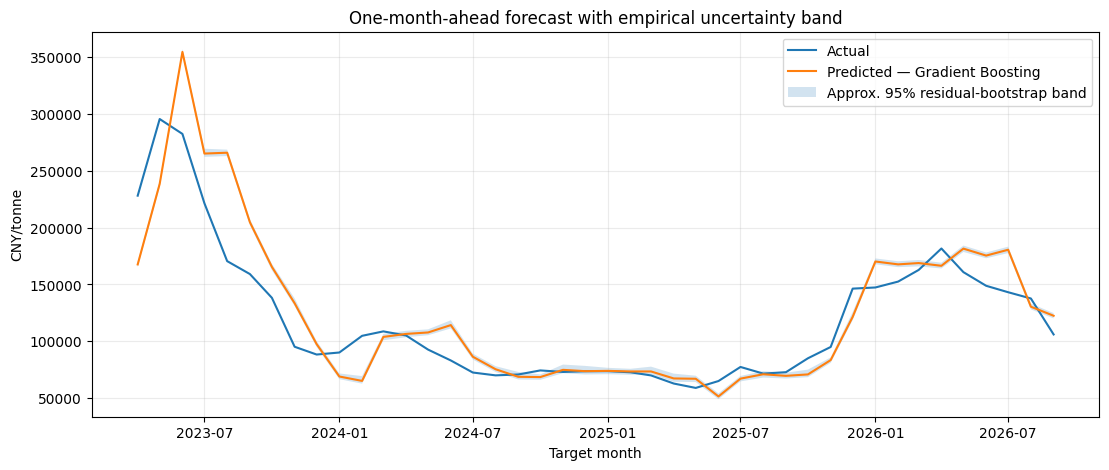

Empirical test coverage: 0.167


In [19]:
# Refit the best one-month univariate model on the chronological training segment.
uni_1 = uni[uni["Horizon (months)"]==1].sort_values("RMSE")
best_name = uni_1.iloc[0]["Model"]
X, y = make_supervised(horizon=1, n_lags=12, exog_cols=None)
X_train, X_test, y_train, y_test = split_time(X,y)
model = model_bank()[best_name]
model.fit(X_train,y_train)
pred = model.predict(X_test)
train_resid = y_train - model.predict(X_train)

def moving_block_sample(values, n, block=4, rng=None):
    rng = np.random.default_rng(RANDOM_STATE) if rng is None else rng
    values = np.asarray(values)
    out=[]
    while len(out)<n:
        start=rng.integers(0, max(1,len(values)-block+1))
        out.extend(values[start:start+block])
    return np.asarray(out[:n])

rng=np.random.default_rng(RANDOM_STATE)
B=1000
sim=np.vstack([pred + moving_block_sample(train_resid, len(pred), block=4, rng=rng) for _ in range(B)])
lower=np.quantile(sim,0.025,axis=0); upper=np.quantile(sim,0.975,axis=0)
fig,ax=plt.subplots(figsize=(13,5))
ax.plot(y_test.index,y_test.values,label="Actual")
ax.plot(y_test.index,pred,label=f"Predicted — {best_name}")
ax.fill_between(y_test.index,lower,upper,alpha=.2,label="Approx. 95% residual-bootstrap band")
ax.set(title="One-month-ahead forecast with empirical uncertainty band",xlabel="Target month",ylabel="CNY/tonne")
ax.legend(); ax.grid(alpha=.25); plt.show()
print("Empirical test coverage:", np.mean((y_test.values>=lower)&(y_test.values<=upper)).round(3))

## 4. Final forecast (illustrative)
This section fits the selected univariate model using all available labeled history and forecasts the month after the last observed target month. The most recent target observation may be revised or provisional; interpret accordingly.

In [20]:
# Feature row for the month immediately after the final target month.
last_target_month = df[TARGET].dropna().index.max()
X_all, y_all = make_supervised(horizon=1, n_lags=12, exog_cols=None)
final_model = model_bank()[best_name]
final_model.fit(X_all,y_all)
# At forecast origin, use the latest 12 observed target values, in lag order.
x_next = pd.DataFrame([{f"target_lag_{lag}": df[TARGET].shift(lag).loc[last_target_month] for lag in range(0,12)}])
forecast = final_model.predict(x_next)[0]
forecast_month = last_target_month + pd.offsets.MonthBegin(1)
print("Forecast origin:", last_target_month.date())
print("Forecast month:", forecast_month.date())
print(f"Illustrative one-month-ahead forecast: {forecast:,.0f} CNY/tonne")

Forecast origin: 2026-10-01
Forecast month: 2026-11-01
Illustrative one-month-ahead forecast: 101,528 CNY/tonne


## Low / Medium / High Price Regime Classification

In [27]:

# Create historical price features
X_cls = pd.DataFrame(index=df.index)

for lag in range(1, 13):
    X_cls[f"Price_lag_{lag}"] = df[TARGET].shift(lag)

# Predict the following month's price
y_cls = df[TARGET].shift(-1)

# Keep observations with an available target
valid = y_cls.notna()
X_cls = X_cls.loc[valid]
y_cls = y_cls.loc[valid]

# Chronological 80/20 split
split_idx = int(len(X_cls) * 0.80)

X_train_cls = X_cls.iloc[:split_idx]
X_test_cls = X_cls.iloc[split_idx:]

y_train_cls = y_cls.iloc[:split_idx]
y_test_cls = y_cls.iloc[split_idx:]

print("Training observations:", len(X_train_cls))
print("Testing observations:", len(X_test_cls))


Training observations: 166
Testing observations: 42


In [28]:

# Calculate thresholds using training data ONLY
low_threshold = y_train_cls.quantile(0.3333)
high_threshold = y_train_cls.quantile(0.6667)

def classify_price(price):
    if price <= low_threshold:
        return "Low"
    elif price <= high_threshold:
        return "Medium"
    else:
        return "High"

# Assign price regimes
y_train_regime = y_train_cls.apply(classify_price)
y_test_regime = y_test_cls.apply(classify_price)

classes = ["Low", "Medium", "High"]

print("Low threshold:", low_threshold)
print("High threshold:", high_threshold)

print("\nTraining regime distribution:")
print(y_train_regime.value_counts())

print("\nTesting regime distribution:")
print(y_test_regime.value_counts())


Low threshold: 37497.25
High threshold: 82501.1

Training regime distribution:
Selected lithium carbonate price (CNY/t)
Medium    56
Low       55
High      55
Name: count, dtype: int64

Testing regime distribution:
Selected lithium carbonate price (CNY/t)
High      27
Medium    15
Name: count, dtype: int64


In [29]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)
# Logistic Regression pipeline
logistic_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

# Random Forest pipeline
random_forest_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=4,
        min_samples_split=10,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42
    ))
])

# Fit models using training observations
logistic_model.fit(X_train_cls, y_train_regime)
random_forest_model.fit(X_train_cls, y_train_regime)

# Predict test-set regimes
logistic_pred = logistic_model.predict(X_test_cls)
rf_pred = random_forest_model.predict(X_test_cls)

print("Classification models trained successfully.")


Classification models trained successfully.


In [30]:

# Current month's observed price is available when forecasting next month
previous_month_prices = df[TARGET].reindex(X_test_cls.index)

persistence_pred = previous_month_prices.apply(
    lambda price: classify_price(price) if pd.notna(price) else np.nan
)

# Remove any observations without a valid baseline prediction
baseline_valid = persistence_pred.notna()

y_test_baseline = y_test_regime.loc[baseline_valid]
persistence_pred = persistence_pred.loc[baseline_valid]

print("Persistence baseline prepared.")


Persistence baseline prepared.


In [31]:

classification_results = []

predictions_dict = {
    "Logistic Regression": logistic_pred,
    "Random Forest": rf_pred,
    "Persistence Baseline": persistence_pred
}

for name, predictions in predictions_dict.items():

    # Use matching observations for each model
    if name == "Persistence Baseline":
        actual = y_test_baseline
    else:
        actual = y_test_regime

    classification_results.append({
        "Model": name,
        "Accuracy": accuracy_score(actual, predictions),
        "Macro F1": f1_score(
            actual,
            predictions,
            labels=classes,
            average="macro",
            zero_division=0
        )
    })

classification_metrics = pd.DataFrame(classification_results)

display(
    classification_metrics.sort_values(
        "Macro F1",
        ascending=False
    )
)


,Model,Accuracy,Macro F1
2,Persistence Baseline,0.952381,0.632099
1,Random Forest,0.857143,0.562963
0,Logistic Regression,0.714286,0.476190


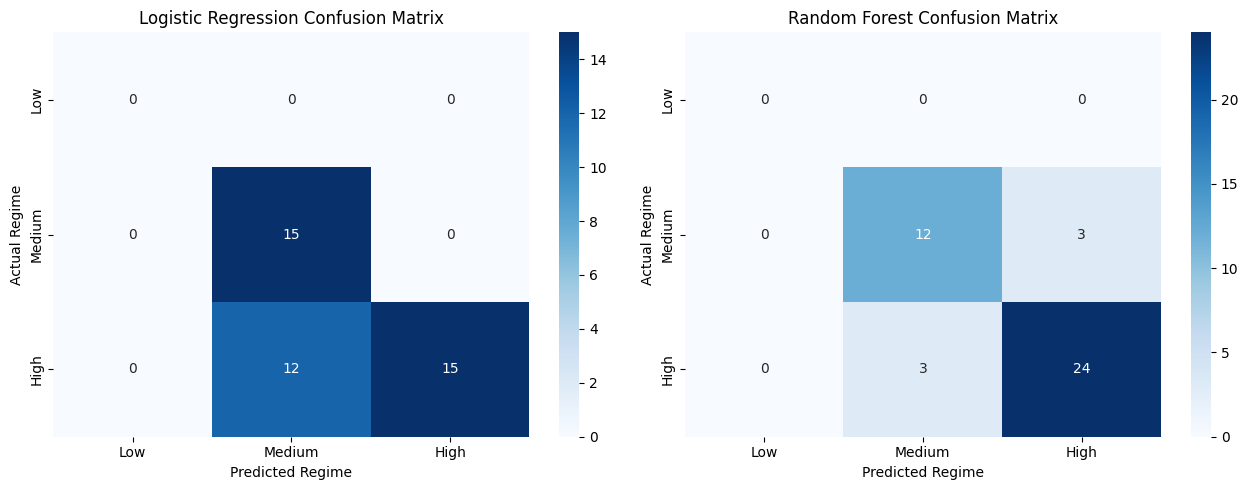

In [33]:
import seaborn as sns
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, name, predictions in [
    (axes[0], "Logistic Regression", logistic_pred),
    (axes[1], "Random Forest", rf_pred)
]:

    cm = confusion_matrix(
        y_test_regime,
        predictions,
        labels=classes
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=classes,
        yticklabels=classes,
        ax=ax
    )

    ax.set_title(f"{name} Confusion Matrix")
    ax.set_xlabel("Predicted Regime")
    ax.set_ylabel("Actual Regime")

plt.tight_layout()
plt.show()


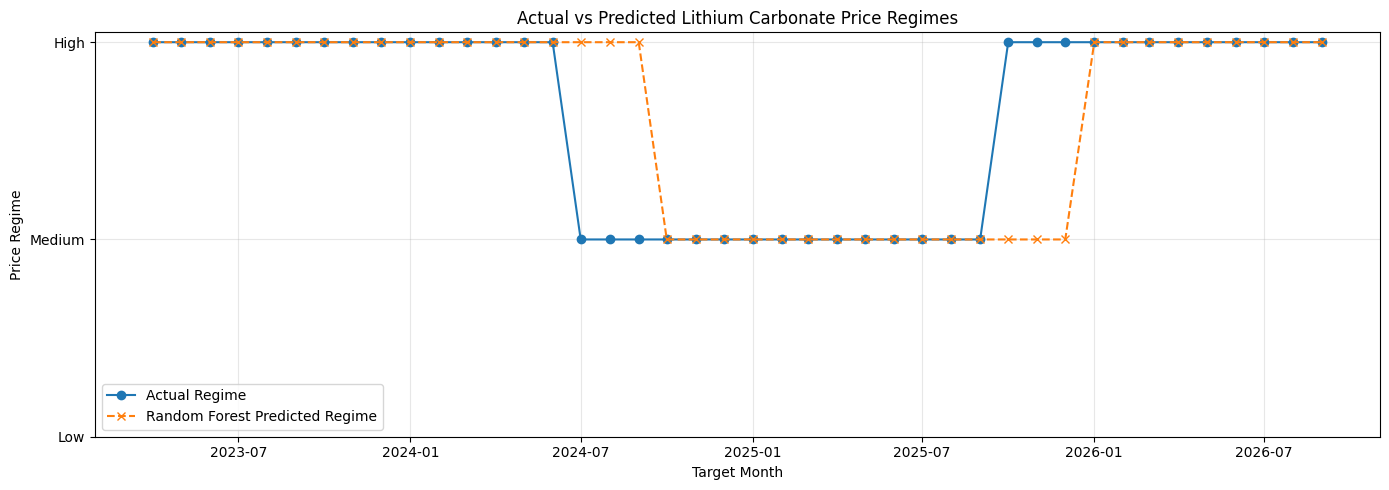

In [34]:

regime_values = {
    "Low": 0,
    "Medium": 1,
    "High": 2
}

actual_numeric = y_test_regime.map(regime_values)
predicted_numeric = pd.Series(
    rf_pred,
    index=y_test_regime.index
).map(regime_values)

plt.figure(figsize=(14, 5))

plt.plot(
    actual_numeric.index,
    actual_numeric,
    marker="o",
    label="Actual Regime"
)

plt.plot(
    predicted_numeric.index,
    predicted_numeric,
    marker="x",
    linestyle="--",
    label="Random Forest Predicted Regime"
)

plt.yticks([0, 1, 2], ["Low", "Medium", "High"])
plt.xlabel("Target Month")
plt.ylabel("Price Regime")
plt.title("Actual vs Predicted Lithium Carbonate Price Regimes")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [35]:

from pathlib import Path

TABLES_DIR = Path("../results/tables")
FIGURES_DIR = Path("../results/figures")

TABLES_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Save classification metrics
classification_metrics.to_csv(
    TABLES_DIR / "low_medium_high_classification_metrics.csv",
    index=False
)

# Save predictions
classification_predictions = pd.DataFrame({
    "Actual Regime": y_test_regime,
    "Logistic Regression": logistic_pred,
    "Random Forest": rf_pred,
    "Persistence Baseline": persistence_pred.reindex(y_test_regime.index)
})

classification_predictions.to_csv(
    TABLES_DIR / "low_medium_high_regime_predictions.csv"
)

print("Classification tables saved successfully.")


Classification tables saved successfully.


## 5. Limitations and next steps

- The target has a longer history than the Japan import-price index; do not swap the target for the Japan index just to increase sample size.
- The Japan index is a yen-based import-price index with base year 2020 = 100, not a directly comparable CNY/tonne spot price.
- Predictor availability and publication lags can create real-time data leakage. This project uses lags, but publication timing should be verified for a production-grade backtest.
- Target source stitching and any methodology changes should be documented.
- A single chronological holdout is useful for a class project, but rolling-origin validation is a stronger next step.
- Bootstrap bands are empirical and should not be described as guaranteed 95% coverage.

In [21]:
comparison.to_csv("../../Results/all_model_comparisons.csv", index=False)
print("Saved ../../Results/all_model_comparisons.csv")

Saved ../../Results/all_model_comparisons.csv
